Name: Pathri Vidya Praveen

Roll Number: CS24BTECH11047

Course: CS3390 Foundations of Machine Learning

Assignment 1

Note: This assignment has been completed by me individually. I do not have a second team member. The data collection for the Mess Food Completion-Time Prediction was carried out with the assistance of a friend who is not registered for this course.


These below solution have been written by hand in the PDF submission.  
  
Question 2 - (a)  
Question 3 - (a),(b)  
Question 4  
Question 5

**1. Mess Food Completion-Time Prediction**

In [2]:
import numpy as np
import pandas as pd

columns = ['date', 'day', 'day_type', 'meal', 'person', 'arrival_time', 'queue_length', 'waiting_time_min', 'completion_time_min', 'food_rating', 'num_dishes', 'skipped']

rows = [
    ('2026-09-13', 'Sunday', 'Holiday', 'Breakfast', 'P1', '08:05', 3, 5, 35, 4.5, 3, 0),
    ('2026-09-13', 'Sunday', 'Holiday', 'Breakfast', 'P2', '08:50', 20, 13, 50, 4.5, 3, 0),
    ('2026-09-13', 'Sunday', 'Holiday', 'Lunch', 'P1', '13:27', 5, 6, 28, 3, 4, 0),
    ('2026-09-13', 'Sunday', 'Holiday', 'Lunch', 'P2', '13:27', 6, 6, 23, 3, 4, 0),
    ('2026-09-13', 'Sunday', 'Holiday', 'Tea', 'P1', '17:05', 9, 4, 15, 5, 3, 0),
    ('2026-09-13', 'Sunday', 'Holiday', 'Tea', 'P2', '17:05', 8, 3, 18, 5, 3, 0),
    ('2026-09-13', 'Sunday', 'Holiday', 'Dinner', 'P1', '20:00', 35, 20, 50, 5, 2, 0),
    ('2026-09-13', 'Sunday', 'Holiday', 'Dinner', 'P2', '20:00', 39, 25, 57, 5, 2, 0),
    ('2026-09-14', 'Monday', 'Festival', 'Breakfast', 'P1', '08:00', 5, 3, 20, 2, 2, 0),
    ('2026-09-14', 'Monday', 'Festival', 'Breakfast', 'P2', '08:13', 7, 5, 25, 2, 2, 0),
    ('2026-09-14', 'Monday', 'Festival', 'Lunch', 'P1', '13:20', 4, 6, 20, 2.5, 3, 0),
    ('2026-09-14', 'Monday', 'Festival', 'Lunch', 'P2', '13:45', 3, 4, 28, 2.5, 3, 0),
    ('2026-09-14', 'Monday', 'Festival', 'Tea', 'P1', '17:00', 15, 6, 17, 5, 2, 0),
    ('2026-09-14', 'Monday', 'Festival', 'Tea', 'P2', '17:00', 17, 10, 20, 5, 2, 0),
    ('2026-09-14', 'Monday', 'Festival', 'Dinner', 'P1', '19:30', 6, 3, 23, 3, 4, 0),
    ('2026-09-14', 'Monday', 'Festival', 'Dinner', 'P2', '19:41', 4, 4, 26, 3, 4, 0),
    ('2026-09-15', 'Tuesday', 'Working', 'Breakfast', 'P1', '08:30', 16, 3, 27, 5, 3, 0),
    ('2026-09-15', 'Tuesday', 'Working', 'Breakfast', 'P2', '08:05', 7, 2, 30, 5, 3, 0),
    ('2026-09-15', 'Tuesday', 'Working', 'Lunch', 'P1', '13:33', 0, 1, 10, 2.5, 2, 0),
    ('2026-09-15', 'Tuesday', 'Working', 'Lunch', 'P2', '13:33', 1, 2, 13, 2.5, 2, 0),
    ('2026-09-15', 'Tuesday', 'Working', 'Tea', 'P1', '17:35', 3, 6, 20, 5, 2, 0),
    ('2026-09-15', 'Tuesday', 'Working', 'Tea', 'P2', '17:05', 6, 3, 27, 5, 2, 0),
    ('2026-09-15', 'Tuesday', 'Working', 'Dinner', 'P1', '20:07', 12, 2, 29, 3.5, 3, 0),
    ('2026-09-15', 'Tuesday', 'Working', 'Dinner', 'P2', '20:07', 9, 5, 38, 3.5, 3, 0),
    ('2026-09-16', 'Wednesday', 'Working', 'Breakfast', 'P1', '09:34', 23, 13, 19, 3, 2, 0),
    ('2026-09-16', 'Wednesday', 'Working', 'Breakfast', 'P2', '08:30', 7, 7, 26, 3, 2, 0),
    ('2026-09-16', 'Wednesday', 'Working', 'Lunch', 'P1', '13:34', 5, 7, 23, 2.5, 3, 0),
    ('2026-09-16', 'Wednesday', 'Working', 'Lunch', 'P2', '13:39', 3, 4, 20, 2.5, 3, 0),
    ('2026-09-16', 'Wednesday', 'Working', 'Tea', 'P1', '17:25', 4, 2, 14, 4.5, 2, 0),
    ('2026-09-16', 'Wednesday', 'Working', 'Tea', 'P2', '17:00', 0, 0, 16, 4.5, 2, 0),
    ('2026-09-16', 'Wednesday', 'Working', 'Dinner', 'P1', '19:45', 20, 23, 45, 5, 3, 0),
    ('2026-09-16', 'Wednesday', 'Working', 'Dinner', 'P2', '19:45', 21, 21, 42, 5, 3, 0),
    ('2026-09-17', 'Thursday', 'Working', 'Breakfast', 'P1', '08:35', 6, 3, 26, 4, 3, 0),
    ('2026-09-17', 'Thursday', 'Working', 'Breakfast', 'P2', '08:20', 3, 6, 27, 4, 3, 0),
    ('2026-09-17', 'Thursday', 'Working', 'Lunch', 'P1', '14:04', 21, 14, 38, 3, 3, 0),
    ('2026-09-17', 'Thursday', 'Working', 'Lunch', 'P2', '12:40', 10, 6, 29, 3, 3, 0),
    ('2026-09-17', 'Thursday', 'Working', 'Tea', 'P1', '17:28', 4, 3, 15, 5, 2, 0),
    ('2026-09-17', 'Thursday', 'Working', 'Tea', 'P2', np.nan, np.nan, np.nan, np.nan, 5, 2, 1),
    ('2026-09-17', 'Thursday', 'Working', 'Dinner', 'P1', '20:23', 8, 6, 23, 3, 3, 0),
    ('2026-09-17', 'Thursday', 'Working', 'Dinner', 'P2', '20:23', 7, 6, 26, 3, 3, 0),
    ('2026-09-18', 'Friday', 'Working', 'Breakfast', 'P1', '08:05', 4, 6, 20, 4, 3, 0),
    ('2026-09-18', 'Friday', 'Working', 'Breakfast', 'P2', '09:50', 17, 14, 38, 4, 3, 0),
    ('2026-09-18', 'Friday', 'Working', 'Lunch', 'P1', '13:20', 5, 6, 28, 3, 2, 0),
    ('2026-09-18', 'Friday', 'Working', 'Lunch', 'P2', '13:27', 8, 7, 27, 3, 2, 0),
    ('2026-09-18', 'Friday', 'Working', 'Tea', 'P1', np.nan, np.nan, np.nan, np.nan, 3, 2, 1),
    ('2026-09-18', 'Friday', 'Working', 'Tea', 'P2', '17:05', 5, 3, 15, 3, 2, 0),
    ('2026-09-18', 'Friday', 'Working', 'Dinner', 'P1', '20:06', 13, 9, 30, 5, 3, 0),
    ('2026-09-18', 'Friday', 'Working', 'Dinner', 'P2', '20:30', 25, 17, 49, 5, 3, 0),
    ('2026-09-19', 'Saturday', 'Holiday', 'Breakfast', 'P1', '08:15', 7, 4, 30, 5, 3, 0),
    ('2026-09-19', 'Saturday', 'Holiday', 'Breakfast', 'P2', '08:00', 0, 0, 33, 5, 3, 0),
    ('2026-09-19', 'Saturday', 'Holiday', 'Lunch', 'P1', '13:00', 3, 2, 15, 1, 3, 0),
    ('2026-09-19', 'Saturday', 'Holiday', 'Lunch', 'P2', '13:00', 4, 1, 17, 1, 3, 0),
    ('2026-09-19', 'Saturday', 'Holiday', 'Tea', 'P1', '17:08', 6, 9, 25, 5, 2, 0),
    ('2026-09-19', 'Saturday', 'Holiday', 'Tea', 'P2', '17:15', 11, 12, 32, 5, 2, 0),
    ('2026-09-19', 'Saturday', 'Holiday', 'Dinner', 'P1', '20:09', 6, 4, 32, 3.5, 3, 0),
    ('2026-09-19', 'Saturday', 'Holiday', 'Dinner', 'P2', '20:14', 8, 5, 39, 3.5, 3, 0),
    ('2026-09-20', 'Sunday', 'Holiday', 'Breakfast', 'P1', '09:00', 12, 8, 40, 4.5, 3, 0),
    ('2026-09-20', 'Sunday', 'Holiday', 'Breakfast', 'P2', '09:00', 13, 7, 36, 4.5, 3, 0),
    ('2026-09-20', 'Sunday', 'Holiday', 'Lunch', 'P1', '13:00', 0, 0, 12, 3, 4, 0),
    ('2026-09-20', 'Sunday', 'Holiday', 'Lunch', 'P2', '13:38', 15, 10, 31, 3, 4, 0),
    ('2026-09-20', 'Sunday', 'Holiday', 'Tea', 'P1', '17:20', 10, 5, 27, 5, 3, 0),
    ('2026-09-20', 'Sunday', 'Holiday', 'Tea', 'P2', '17:15', 12, 8, 31, 5, 3, 0),
    ('2026-09-20', 'Sunday', 'Holiday', 'Dinner', 'P1', '20:35', 21, 9, 37, 4, 2, 0),
    ('2026-09-20', 'Sunday', 'Holiday', 'Dinner', 'P2', '20:31', 19, 10, 47, 4, 2, 0),
    ('2026-09-21', 'Monday', 'Working', 'Breakfast', 'P1', '08:35', 18, 12, 41, 3.5, 4, 0),
    ('2026-09-21', 'Monday', 'Working', 'Breakfast', 'P2', '08:35', 18, 13, 41, 3.5, 4, 0),
    ('2026-09-21', 'Monday', 'Working', 'Lunch', 'P1', '13:15', 13, 5, 18, 2, 3, 0),
    ('2026-09-21', 'Monday', 'Working', 'Lunch', 'P2', '13:15', 13, 3, 20, 2, 3, 0),
    ('2026-09-21', 'Monday', 'Working', 'Tea', 'P1', '17:20', 18, 11, 23, 4.5, 2, 0),
    ('2026-09-21', 'Monday', 'Working', 'Tea', 'P2', '17:20', 20, 11, 26, 4.5, 2, 0),
    ('2026-09-21', 'Monday', 'Working', 'Dinner', 'P1', '19:45', 8, 9, 32, 2.5, 3, 0),
    ('2026-09-21', 'Monday', 'Working', 'Dinner', 'P2', '19:45', 10, 7, 34, 2.5, 3, 0),
    ('2026-09-22', 'Tuesday', 'Working', 'Breakfast', 'P1', np.nan, np.nan, np.nan, np.nan, 5, 3, 1),
    ('2026-09-22', 'Tuesday', 'Working', 'Breakfast', 'P2', '08:40', 18, 12, 42, 5, 3, 0),
    ('2026-09-22', 'Tuesday', 'Working', 'Lunch', 'P1', '13:45', 10, 4, 22, 2.5, 2, 0),
    ('2026-09-22', 'Tuesday', 'Working', 'Lunch', 'P2', '13:55', 3, 6, 26, 2.5, 2, 0),
    ('2026-09-22', 'Tuesday', 'Working', 'Tea', 'P1', '17:33', 12, 2, 21, 5, 2, 0),
    ('2026-09-22', 'Tuesday', 'Working', 'Tea', 'P2', '17:33', 12, 4, 15, 5, 2, 0),
    ('2026-09-22', 'Tuesday', 'Working', 'Dinner', 'P1', '19:45', 10, 4, 34, 3, 3, 0),
    ('2026-09-22', 'Tuesday', 'Working', 'Dinner', 'P2', '20:00', 18, 12, 33, 3, 3, 0),
    ('2026-09-23', 'Wednesday', 'Working', 'Breakfast', 'P1', '08:42', 12, 7, 23, 2, 2, 0),
    ('2026-09-23', 'Wednesday', 'Working', 'Breakfast', 'P2', '08:42', 13, 6, 26, 2, 2, 0),
    ('2026-09-23', 'Wednesday', 'Working', 'Lunch', 'P1', '12:54', 0, 5, 14, 2, 3, 0),
    ('2026-09-23', 'Wednesday', 'Working', 'Lunch', 'P2', '12:54', 1, 5, 14, 2, 3, 0),
    ('2026-09-23', 'Wednesday', 'Working', 'Tea', 'P1', '17:05', 10, 3, 25, 4.5, 2, 0),
    ('2026-09-23', 'Wednesday', 'Working', 'Tea', 'P2', '17:06', 12, 9, 25, 4.5, 2, 0),
    ('2026-09-23', 'Wednesday', 'Working', 'Dinner', 'P1', '19:50', 18, 15, 45, 5, 3, 0),
    ('2026-09-23', 'Wednesday', 'Working', 'Dinner', 'P2', '19:50', 16, 13, 33, 5, 3, 0),
    ('2026-09-24', 'Thursday', 'Working', 'Breakfast', 'P1', '08:45', 17, 16, 31, 4, 2, 0),
    ('2026-09-24', 'Thursday', 'Working', 'Breakfast', 'P2', '08:29', 17, 13, 42, 4, 2, 0),
    ('2026-09-24', 'Thursday', 'Working', 'Lunch', 'P1', '12:35', 0, 1, 25, 3, 3, 0),
    ('2026-09-24', 'Thursday', 'Working', 'Lunch', 'P2', '12:35', 0, 0, 22, 3, 3, 0),
    ('2026-09-24', 'Thursday', 'Working', 'Tea', 'P1', '17:05', 9, 8, 22, 5, 2, 0),
    ('2026-09-24', 'Thursday', 'Working', 'Tea', 'P2', np.nan, np.nan, np.nan, np.nan, 5, 2, 1),
    ('2026-09-24', 'Thursday', 'Working', 'Dinner', 'P1', '20:15', 19, 13, 39, 3, 3, 0),
    ('2026-09-24', 'Thursday', 'Working', 'Dinner', 'P2', '19:52', 22, 10, 41, 3, 3, 0),
    ('2026-09-25', 'Friday', 'Working', 'Breakfast', 'P1', '09:31', 6, 5, 28, 4.5, 3, 0),
    ('2026-09-25', 'Friday', 'Working', 'Breakfast', 'P2', '09:31', 6, 6, 19, 4.5, 3, 0),
    ('2026-09-25', 'Friday', 'Working', 'Lunch', 'P1', '12:55', 4, 0, 11, 2.5, 2, 0),
    ('2026-09-25', 'Friday', 'Working', 'Lunch', 'P2', '12:55', 3, 0, 19, 2.5, 2, 0),
    ('2026-09-25', 'Friday', 'Working', 'Tea', 'P1', '17:30', 7, 3, 22, 2, 3, 0),
    ('2026-09-25', 'Friday', 'Working', 'Tea', 'P2', '17:30', 6, 4, 18, 2, 3, 0),
    ('2026-09-25', 'Friday', 'Working', 'Dinner', 'P1', '20:20', 23, 15, 34, 4.5, 3, 0),
    ('2026-09-25', 'Friday', 'Working', 'Dinner', 'P2', '19:55', 19, 12, 46, 4.5, 3, 0),
    ('2026-09-26', 'Saturday', 'Holiday', 'Breakfast', 'P1', '09:32', 13, 12, 41, 5, 2, 0),
    ('2026-09-26', 'Saturday', 'Holiday', 'Breakfast', 'P2', '08:15', 13, 9, 36, 5, 2, 0),
    ('2026-09-26', 'Saturday', 'Holiday', 'Lunch', 'P1', '13:43', 7, 10, 30, 1.5, 3, 0),
    ('2026-09-26', 'Saturday', 'Holiday', 'Lunch', 'P2', '12:50', 1, 1, 13, 1.5, 3, 0),
    ('2026-09-26', 'Saturday', 'Holiday', 'Tea', 'P1', '17:10', 14, 5, 17, 4.5, 2, 0),
    ('2026-09-26', 'Saturday', 'Holiday', 'Tea', 'P2', '17:10', 16, 4, 15, 4.5, 2, 0),
    ('2026-09-26', 'Saturday', 'Holiday', 'Dinner', 'P1', '19:35', 9, 3, 29, 2.5, 3, 0),
    ('2026-09-26', 'Saturday', 'Holiday', 'Dinner', 'P2', '19:40', 18, 11, 35, 2.5, 3, 0),
]

df = pd.DataFrame(rows, columns=columns)
df = df.astype({
    "queue_length": "Int64",
    "waiting_time_min": "Int64",
    "completion_time_min": "Int64",
    "food_rating": "float64",
    "num_dishes": "int64",
    "skipped": "int64",
})
df.to_csv("mess_data.csv", index=False, float_format="%g")
print(df.shape)

(112, 12)


Rows read: 112 | skipped meals filled with mean: 4

(a) EXPLORATORY DATA ANALYSIS:

Summary of the target (minutes):
count    112.00
mean      27.59
std        9.96
min       10.00
25%       20.00
50%       26.00
75%       34.00
max       57.00
Skewness: 0.545

Completion time by meal:
           count   mean   std   min   max
meal                                     
Breakfast     28  31.46  8.28  19.0  50.0
Dinner        28  36.71  8.59  23.0  57.0
Lunch         28  21.29  7.10  10.0  38.0
Tea           28  20.89  5.02  14.0  32.0

Completion time by person:
        count   mean    std   min   max
person                                 
P1         56  26.23   9.22  10.0  50.0
P2         56  28.95  10.55  13.0  57.0

Completion time by day_type:
          count   mean    std   min   max
day_type                                 
Festival      8  22.38   3.74  17.0  28.0
Holiday      32  30.50  11.58  12.0  57.0
Working      72  26.88   9.36  10.0  49.0

Completion time by day:
        

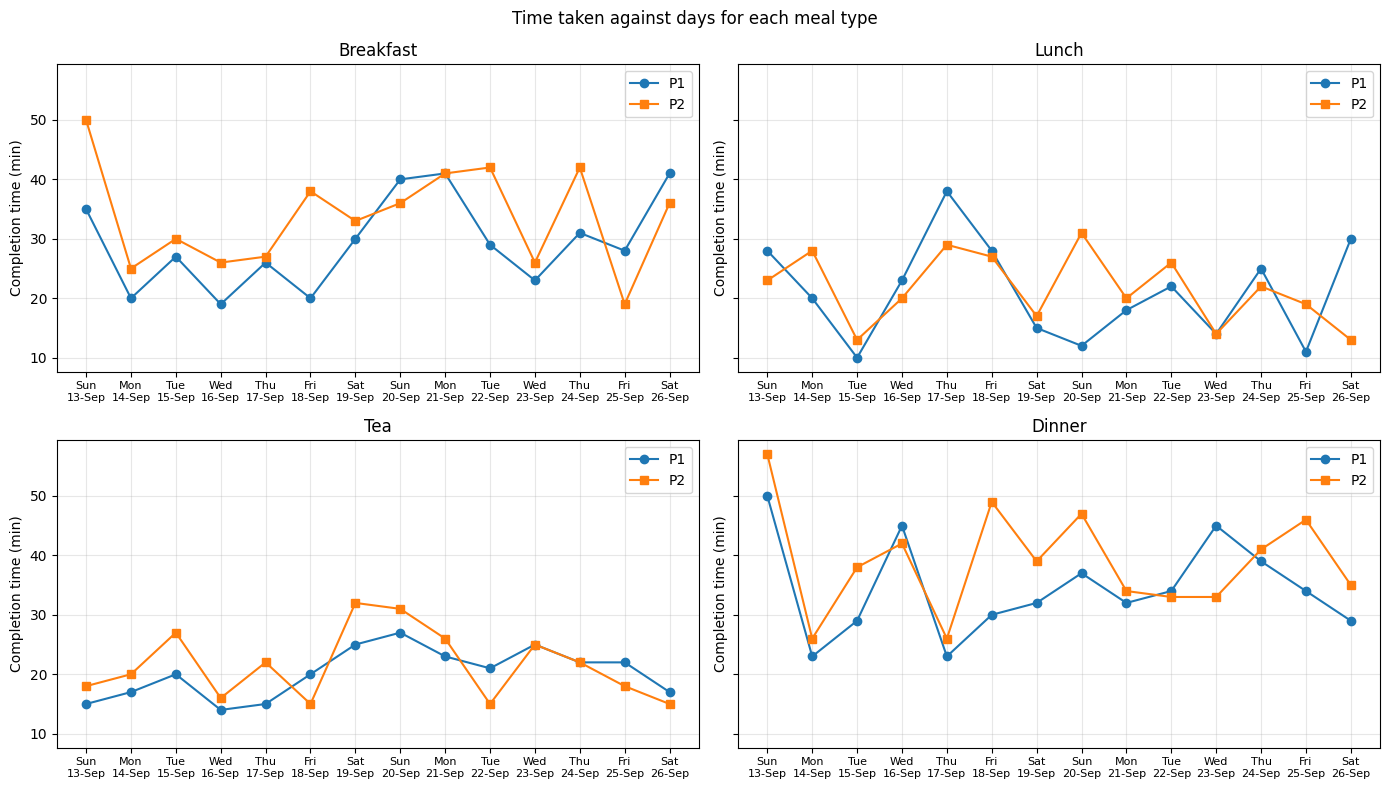

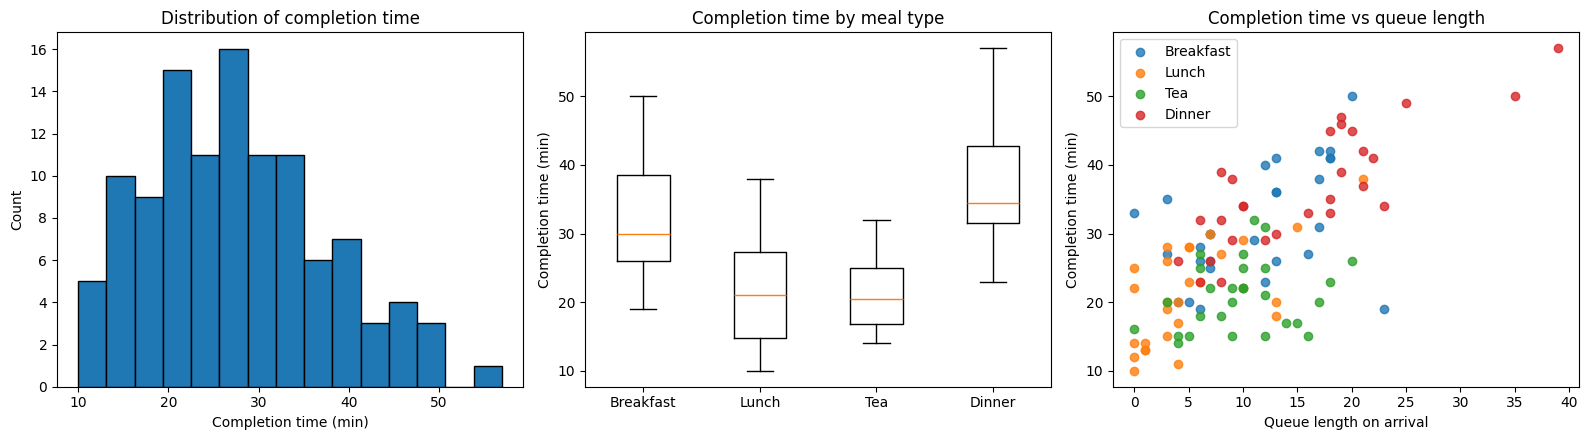


Train rows: 88 | Test rows: 24

(b) GAMMA REGRESSION - MLE)
Converged in 7 iterations | train log-likelihood = -266.354
Shape parameter k = 27.503 (coefficient of variation = 0.191)

Learned parameters:
                  beta  std_err        z  exp(beta)  LR_stat
intercept       3.3221   0.0489  67.9374    27.7185      NaN
meal_Lunch     -0.1107   0.0740  -1.4966     0.8952   2.2428
meal_Tea       -0.3858   0.0621  -6.2123     0.6799  32.1363
meal_Dinner     0.0717   0.0602   1.1910     1.0743   1.4060
person_P2       0.0931   0.0426   2.1847     1.0975   4.6073
is_holiday      0.0516   0.0478   1.0798     1.0529   1.1763
is_festival     0.0515   0.1146   0.4497     1.0529   0.2043
log_queue       0.1700   0.0281   6.0469     1.1853  30.1441
food_rating     0.1065   0.0280   3.8088     1.1124  13.3638
num_dishes      0.0580   0.0237   2.4431     1.0597   5.8799
arrival_offset  0.0238   0.0221   1.0746     1.0241   1.1497

Parameters ranked by importance (likelihood-ratio statistic):
 

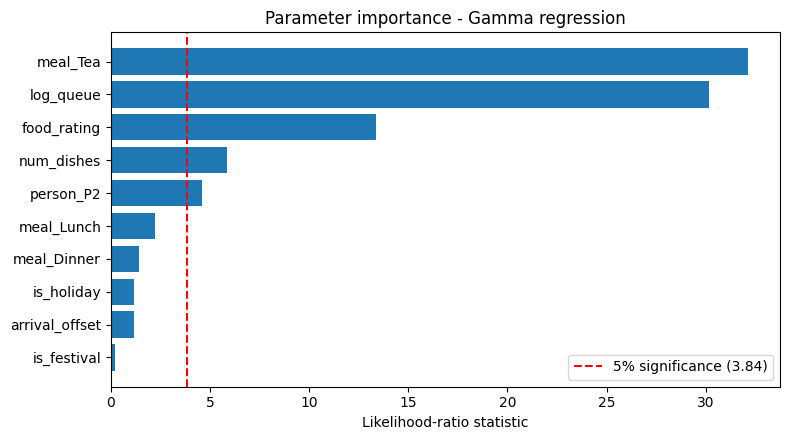


(c) PREDICTION ON TEST SPLIT
                          MAE   RMSE  MAPE_%
Gamma regression (MLE)  5.571  6.674  22.887
Linear regression       5.885  6.918  24.606

Lower test MAE: Gamma regression (MLE)


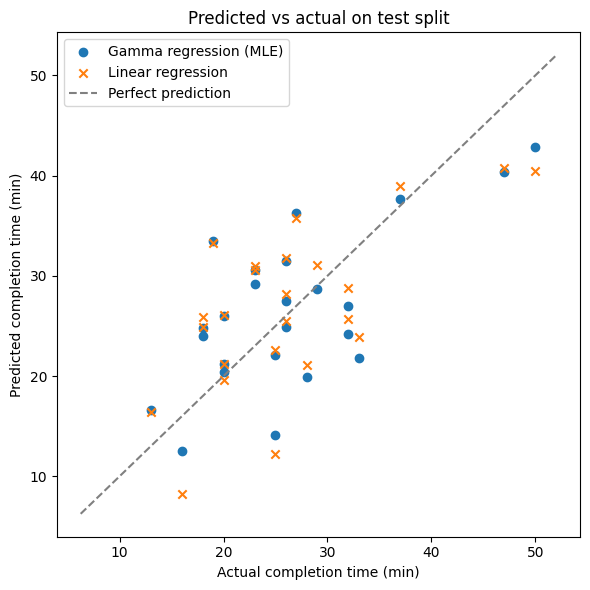

In [4]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

DATA_PATH = "mess_data.csv"
TARGET = "completion_time_min"
MEALS = ["Breakfast", "Lunch", "Tea", "Dinner"]
SEED = 42
TRAIN_FRACTION = 0.8


# (a) data preparation
def load_and_clean(path):
    # read raw csv , fill skipped meals and fix column types
    df = pd.read_csv(path)
    n_raw = len(df)
    df = df.drop_duplicates()
    # skipped meals have no recorded values - filling them with mean of same group
    groups = df.groupby(["meal", "person"])
    for column in ["queue_length","waiting_time_min",TARGET]:
        df[column] = df[column].fillna(groups[column].transform("mean").round())
    hhmm = df["arrival_time"].str.split(":", expand=True).astype(float)
    minutes = hhmm[0]*60 + hhmm[1]
    minutes = minutes.fillna(minutes.groupby([df["meal"], df["person"]]).transform("mean")).round()
    df["arrival_time"] = [f"{int(m//60):02d}:{int(m%60):02d}" for m in minutes]
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values(["date", "meal", "person"]).reset_index(drop=True)
    print(f"Rows read: {n_raw} | skipped meals filled with mean: {int(df['skipped'].sum())}")
    return df


def add_features(df):
    df = df.copy()
    hhmm = df["arrival_time"].str.split(":", expand=True).astype(int)
    df["arrival_min"] = hhmm[0]*60 + hhmm[1]
    # one hot encoding meal type
    for meal in MEALS[1:]:
        df[f"meal_{meal}"] = (df["meal"] == meal).astype(float)
    df["person_P2"] = (df["person"] == "P2").astype(float)
    df["is_holiday"] = (df["day_type"] == "Holiday").astype(float)
    df["is_festival"] = (df["day_type"] == "Festival").astype(float)
    df["log_queue"] = np.log1p(df["queue_length"])
    return df

BINARY_FEATURES = ["meal_Lunch", "meal_Tea", "meal_Dinner","person_P2", "is_holiday", "is_festival"]
NUMERIC_FEATURES = ["log_queue", "food_rating", "num_dishes", "arrival_offset"]
FEATURES = BINARY_FEATURES + NUMERIC_FEATURES


def train_test_split(df, train_fraction, seed):
    # random 80-20 split done separately inside each meal type
    rng = np.random.default_rng(seed)
    train_idx = []
    for _,group in df.groupby("meal"):
        idx = rng.permutation(group.index.to_numpy())
        train_idx.extend(idx[: int(round(train_fraction *len(idx)))])
    train = df.loc[sorted(train_idx)]
    test = df.drop(index=train_idx)
    return train, test


def build_design_matrices(train, test):
    # build X for train,test. All statistics computed on training split
    train, test = train.copy(),test.copy()
    usual_arrival = train.groupby("meal")["arrival_min"].mean()
    for part in (train, test):
        part["arrival_offset"] = part["arrival_min"] - part["meal"].map(usual_arrival)
    mean = train[NUMERIC_FEATURES].mean()
    std = train[NUMERIC_FEATURES].std().replace(0,1.0)
    for part in (train, test):
        part[NUMERIC_FEATURES] = (part[NUMERIC_FEATURES]-mean) / std

    def to_matrix(part):
        X = part[FEATURES].to_numpy(dtype=float)
        return np.column_stack([np.ones(len(X)),X])

    return to_matrix(train), to_matrix(test)


# (a) exploratory data analysis
def run_eda(df):
    # print summary stats and draw EDA plots
    print("\n(a) EXPLORATORY DATA ANALYSIS:")
    print("\nSummary of the target (minutes):")
    print(df[TARGET].describe().round(2).to_string())
    print(f"Skewness: {df[TARGET].skew():.3f}")

    for column in ["meal","person","day_type","day"]:
        print(f"\nCompletion time by {column}:")
        print(df.groupby(column)[TARGET].agg(["count", "mean", "std", "min", "max"]).round(2).to_string())

    numeric = ["queue_length", "waiting_time_min", "food_rating", "num_dishes","arrival_min", TARGET]
    print("\nCorrelation with completion time:")
    print(df[numeric].corr()[TARGET].drop(TARGET).round(3).to_string())
    # plot of time taken against days, 1 panel per meal type
    fig, axes = plt.subplots(2, 2, figsize=(14,8), sharey=True)
    for ax, meal in zip(axes.ravel(), MEALS):
        sub = df[df["meal"] == meal]
        for person, marker in zip(["P1","P2"], ["o","s"]):
            p = sub[sub["person"] == person]
            ax.plot(p["date"], p[TARGET], marker=marker,label=person)
        ax.set_title(meal)
        ax.set_ylabel("Completion time (min)")
        ax.set_xticks(sorted(sub["date"].unique()))
        ax.set_xticklabels([d.strftime("%a\n%d-%b") for d in sorted(sub["date"].unique())],fontsize=8)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle("Time taken against days for each meal type")
    fig.tight_layout()
    fig.savefig("plot_time_vs_day_per_meal.png",dpi=150)
    plt.show()

    # plot of distributiion of target, boc plot by meal and   queuue effect
    fig, axes = plt.subplots(1,3,figsize=(16,4.5))
    axes[0].hist(df[TARGET],bins=15,edgecolor="black")
    axes[0].set_title("Distribution of completion time")
    axes[0].set_xlabel("Completion time (min)")
    axes[0].set_ylabel("Count")
    axes[1].boxplot([df.loc[df["meal"] == m,TARGET] for m in MEALS])
    axes[1].set_xticks(range(1,len(MEALS)+1))
    axes[1].set_xticklabels(MEALS)
    axes[1].set_title("Completion time by meal type")
    axes[1].set_ylabel("Completion time (min)")

    for meal in MEALS:
        sub = df[df["meal"] == meal]
        axes[2].scatter(sub["queue_length"], sub[TARGET], label=meal, alpha=0.8)
    axes[2].set_title("Completion time vs queue length")
    axes[2].set_xlabel("Queue length on arrival")
    axes[2].set_ylabel("Completion time (min)")
    axes[2].legend()
    fig.tight_layout()
    fig.savefig("plot_eda_overview.png", dpi=150)
    plt.show()


# (b) gamma regression fitted by maximum likelihood
def digamma(x):
    result = 0.0
    while x < 6.0:
        result -= 1.0 / x
        x += 1.0
    inv2 = 1.0/(x*x)
    return result + math.log(x) - 0.5/x - inv2*(1/12-inv2*(1/120 -inv2 /252))


def trigamma(x):
    result = 0.0
    while x < 6.0:
        result += 1.0/(x*x)
        x += 1.0
    inv2 = 1.0/(x*x)
    return result + 1.0/x + 0.5*inv2 + (1/6-inv2*(1/30 -inv2/42))/(x**3)


class GammaRegressionMLE:
    def __init__(self, max_iter=200, tol=1e-10):
        self.max_iter = max_iter
        self.tol = tol

    @staticmethod
    def log_likelihood(X, y, beta, k):
        eta = X @ beta
        return float(np.sum(k * math.log(k) - math.lgamma(k) + (k - 1) * np.log(y)- k * eta - k * y * np.exp(-eta)))

    def _fit_shape(self, y, mu):
        ratio = y / mu
        c = float(np.mean(ratio - np.log(ratio) - 1.0))
        k = 1.0 / (2.0 * c)
        for _ in range(100):
            step = (math.log(k) - digamma(k) - c) /(1.0 / k - trigamma(k))
            k_new = k - step
            if k_new <= 0:
                k_new = k / 2.0
            if abs(k_new - k) < 1e-10:
                k = k_new
                break
            k = k_new
        return k

    def fit(self, X, y):
        n, d = X.shape
        beta = np.zeros(d)
        beta[0] = math.log(y.mean())
        k = 1.0
        XtX = X.T @ X
        self.history = []

        for iteration in range(self.max_iter):
            mu = np.exp(X @ beta)
            score = X.T @ (y / mu - 1.0)
            beta = beta + np.linalg.solve(XtX, score)
            k = self._fit_shape(y, np.exp(X @ beta))
            ll = self.log_likelihood(X, y, beta, k)
            self.history.append(ll)
            if iteration > 0 and abs(ll - self.history[-2]) < self.tol:
                break

        self.beta, self.shape = beta, k
        self.n_iter = len(self.history)
        self.std_err = np.sqrt(np.diag(np.linalg.inv(k * XtX)))
        return self

    def predict(self, X):
        # predicted mean completion time
        return np.exp(X @ self.beta)


def analyse_parameters(model, X_train, y_train):
    # print learnt params and rank them by importance
    print("\n(b) GAMMA REGRESSION - MLE)")
    print(f"Converged in {model.n_iter} iterations | train log-likelihood = {model.history[-1]:.3f}")
    print(f"Shape parameter k = {model.shape:.3f} (coefficient of variation = {1 / math.sqrt(model.shape):.3f})")

    names = ["intercept"] + FEATURES
    table = pd.DataFrame({
        "beta": model.beta,
        "std_err": model.std_err,
        "z": model.beta / model.std_err,
        "exp(beta)": np.exp(model.beta),
    }, index=names)

    full_ll = model.history[-1]
    lr_stat = [np.nan]
    for j in range(1, X_train.shape[1]):
        reduced = GammaRegressionMLE().fit(np.delete(X_train, j, axis=1), y_train)
        lr_stat.append(2.0 * (full_ll - reduced.history[-1]))
    table["LR_stat"] = lr_stat
    print("\nLearned parameters:")
    print(table.round(4).to_string())


    ranking = table.drop(index="intercept").sort_values("LR_stat", ascending=False)
    print("\nParameters ranked by importance (likelihood-ratio statistic):")
    print(ranking[["beta", "exp(beta)", "z", "LR_stat"]].round(4).to_string())
    print(f"\nMost important parameter: {ranking.index[0]}")
    fig, ax = plt.subplots(figsize=(8,4.5))
    ax.barh(ranking.index[::-1], ranking["LR_stat"][::-1])
    ax.axvline(3.84, color="red", linestyle="--", label="5% significance (3.84)")
    ax.set_xlabel("Likelihood-ratio statistic")
    ax.set_title("Parameter importance - Gamma regression")
    ax.legend()
    fig.tight_layout()
    fig.savefig("plot_parameter_importance.png", dpi=150)
    plt.show()
    return table


# (c) prediction and comparison with linear regression
def evaluate(y_true, y_pred):
    # MAE, RMSE (min) and MAPE (%)
    error = y_true - y_pred
    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "MAPE_%": float(np.mean(np.abs(error) / y_true) * 100),
    }


def compare_models(model, X_train, y_train, X_test, y_test):
    print("\n(c) PREDICTION ON TEST SPLIT")
    gamma_pred = model.predict(X_test)
    linear = LinearRegression().fit(X_train[:, 1:], y_train)
    linear_pred = linear.predict(X_test[:, 1:])
    results = pd.DataFrame({
        "Gamma regression (MLE)": evaluate(y_test, gamma_pred),
        "Linear regression": evaluate(y_test, linear_pred),
    }).T
    print(results.round(3).to_string())
    best = results["MAE"].idxmin()
    print(f"\nLower test MAE: {best}")
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(y_test, gamma_pred, label="Gamma regression (MLE)", marker="o")
    ax.scatter(y_test, linear_pred, label="Linear regression", marker="x")
    limits = [min(y_test.min(), gamma_pred.min(), linear_pred.min())-2,max(y_test.max(), gamma_pred.max(), linear_pred.max())+2]
    ax.plot(limits, limits, color="grey", linestyle="--", label="Perfect prediction")
    ax.set_xlabel("Actual completion time (min)")
    ax.set_ylabel("Predicted completion time (min)")
    ax.set_title("Predicted vs actual on test split")
    ax.legend()
    fig.tight_layout()
    fig.savefig("plot_predicted_vs_actual.png",dpi=150)
    plt.show()
    return results


# main function
def main():
    df = add_features(load_and_clean(DATA_PATH))
    # (a) exploratory datab analysis
    run_eda(df)
    train, test = train_test_split(df, TRAIN_FRACTION, SEED)
    print(f"\nTrain rows: {len(train)} | Test rows: {len(test)}")
    X_train, X_test = build_design_matrices(train, test)
    y_train, y_test = train[TARGET].to_numpy(float), test[TARGET].to_numpy(float)

    # (b) learn parameters by MLE and analyse them
    model = GammaRegressionMLE().fit(X_train, y_train)
    analyse_parameters(model, X_train, y_train)
    # (c) predict and compare with linear regression
    compare_models(model, X_train, y_train, X_test, y_test)


if __name__ == "__main__":
    main()

## Data and pre-processing
- 2 persons (P1, P2) × 14 days (13–26 Sep 2026) × 4 meals = 112 rows. Target: `completion_time_min` (waiting + eating).
- The 4 skipped meals are filled with the mean of the same meal and person.
- Categorical columns are one-hot encoded; continuous features are standardised with training statistics.
- 80/20 random split, stratified by meal: 88 train, 24 test.

## Features
| Feature | Reason |
|---|---|
| Meal type (Lunch, Tea, Dinner vs Breakfast) | Meals differ in size and crowd |
| Person (P2 vs P1) | Different eating pace |
| Holiday, Festival (vs Working) | Less rush on non-working days |
| `log(1 + queue_length)` | Queue on arrival drives the waiting time |
| `food_rating` | Better food, more servings, slower eating |
| `num_dishes` | More dishes take longer to serve and eat |
| `arrival_offset` | Early or late arrival relative to the usual time of that meal |

`waiting_time_min` is not used: it is part of the target and known only after the wait (leakage). Day of week is not used: 7 categories is too many for 88 rows.

## (a) EDA
- Completion time: 10–57 min, mean 27.6, positive and right-skewed (skewness 0.55).
- Dinner (36.7 min) and Breakfast (31.5) take longer than Lunch (21.3) and Tea (20.9).
- Queue length has the strongest correlation with completion time (0.69); food rating is next (0.34).
- P2 is slower than P1 (29.0 vs 26.2 min); Sunday is the slowest day (33.6 min).

## (b) Model: Gamma regression fitted by MLE
Linear regression assumes symmetric noise with constant variance and can predict negative times. Completion time is positive, right-skewed, and its spread grows with its mean, so:

$$y_i \sim \text{Gamma}\left(k,\ \tfrac{\mu_i}{k}\right), \qquad \mu_i = \exp(x_i^\top \beta)$$

$$\ell(\beta, k) = \sum_i \left[ k\log k - \log\Gamma(k) + (k-1)\log y_i - k\log\mu_i - \frac{k\,y_i}{\mu_i} \right]$$

- $\beta$ is learned by Fisher scoring: $\beta \leftarrow \beta + (X^\top X)^{-1} X^\top (y/\mu - 1)$.
- $k$ is learned by Newton's method on $\log k - \psi(k) = \text{mean}\left(y/\mu - \log(y/\mu) - 1\right)$.
- Converged in 7 iterations; $k = 27.5$ (noise is about 19% of the mean).

**Parameter importance** (likelihood-ratio statistic: drop the feature, refit, take twice the fall in log-likelihood; above 3.84 is significant at 5%):

| Parameter | $\beta$ | $e^{\beta}$ | LR statistic |
|---|---|---|---|
| `meal_Tea` | -0.386 | 0.68 | 32.1 |
| `log_queue` | 0.170 | 1.19 | 30.1 |
| `food_rating` | 0.107 | 1.11 | 13.4 |
| `num_dishes` | 0.058 | 1.06 | 5.9 |
| `person_P2` | 0.093 | 1.10 | 4.6 |
| `meal_Lunch` | -0.111 | 0.90 | 2.2 |
| `meal_Dinner` | 0.072 | 1.07 | 1.4 |
| `is_holiday` | 0.052 | 1.05 | 1.2 |
| `arrival_offset` | 0.024 | 1.02 | 1.1 |
| `is_festival` | 0.052 | 1.05 | 0.2 |

- Most important: **meal type (Tea)** and **queue length**. Tea is 32% shorter than Breakfast; one standard deviation more of log-queue adds 19%.
- Food rating (+11%), number of dishes (+6%) and person (P2 +10%) are also significant.
- Holiday, festival, arrival offset, Lunch and Dinner are not significant. Dinner looks slow in the EDA mainly because its queues are long.

## (c) Prediction and comparison
Metrics on the 24 test rows: MAE (main metric) and RMSE in minutes, and MAPE as a relative error.

| Model | MAE (min) | RMSE (min) | MAPE (%) |
|---|---|---|---|
| Gamma regression (MLE) | 5.57 | 6.67 | 22.9 |
| Linear regression (scikit-learn) | 5.89 | 6.92 | 24.6 |

Both models use the same features. Gamma regression is better on all three metrics; the gap is small because the test set has only 24 rows.

**2. Dimensionality Reduction using PCA on MNIST**  
**Part (b),(c)**

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to dataset files: /kaggle/input/mnist-dataset
Train: (60000, 784), Test: (10000, 784)

(i) Variance explained
Total variance (trace of covariance): 52.7259
PC1: eigenvalue = 5.1169, ratio = 9.70%
PC2: eigenvalue = 3.7414, ratio = 7.10%
Cumulative (PC1 + PC2): 16.80%


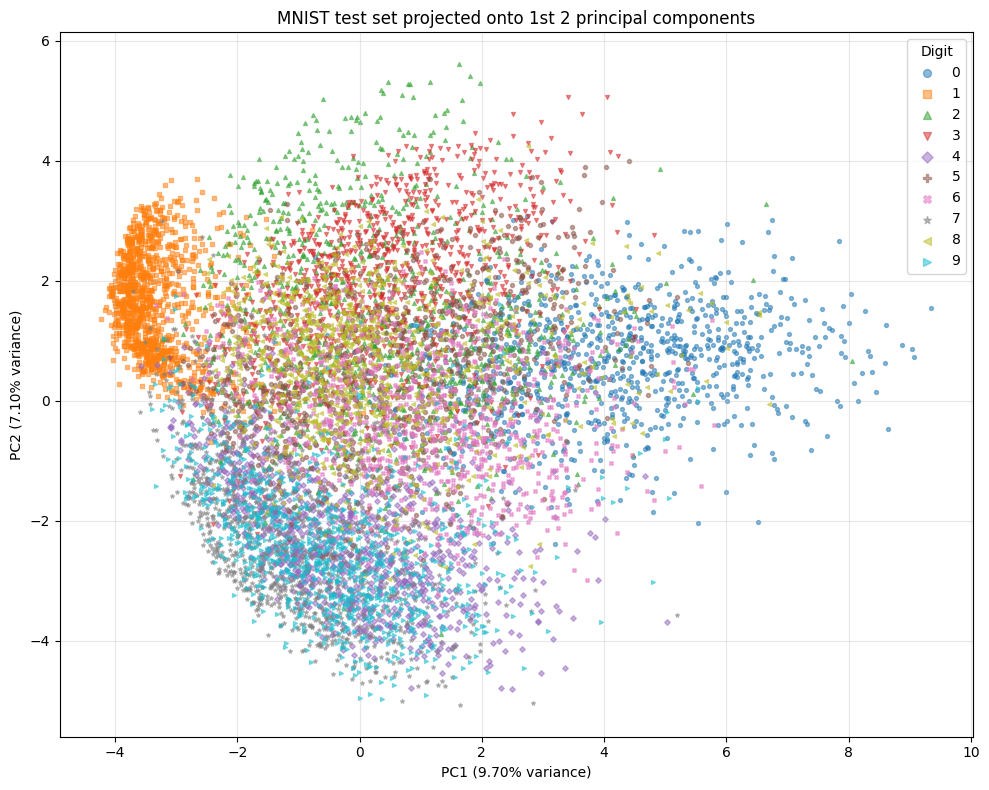

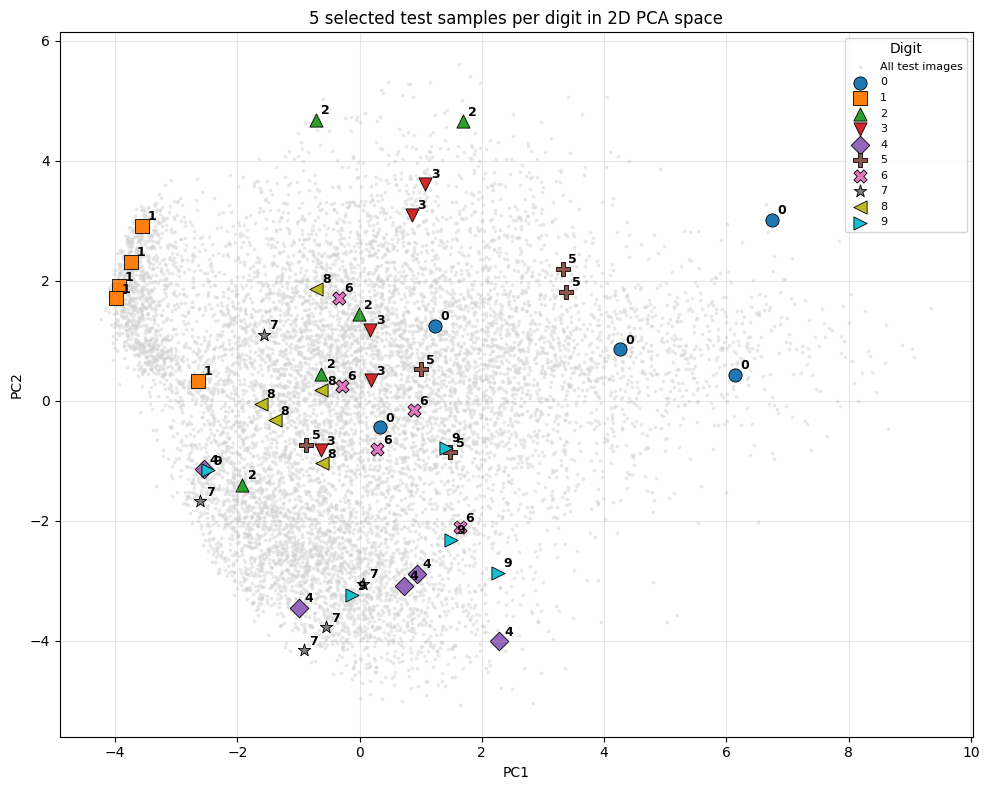


(iii) Per-class statistics on full test set (PC space)
digit  mean PC1  mean PC2  std PC1  std PC2
    0     4.016     0.615    1.865    0.915
    1    -3.327     1.635    0.556    0.834
    2     0.374     1.417    1.620    1.544
    3     0.357     1.912    1.423    1.259
    4    -0.265    -2.308    1.397    1.045
    5     0.539     0.543    1.633    1.233
    6     1.056    -0.233    1.641    1.067
    7    -1.042    -2.280    1.244    1.325
    8     0.156     0.632    1.571    1.126
    9    -0.469    -2.387    1.422    1.126

(iv) Reconstruction error with 2 PCs (selected images)
Mean per-pixel MSE: 0.0552
Digit 0: mean MSE = 0.0649
Digit 1: mean MSE = 0.0276
Digit 2: mean MSE = 0.0613
Digit 3: mean MSE = 0.0606
Digit 4: mean MSE = 0.0479
Digit 5: mean MSE = 0.0657
Digit 6: mean MSE = 0.0712
Digit 7: mean MSE = 0.0460
Digit 8: mean MSE = 0.0521
Digit 9: mean MSE = 0.0547


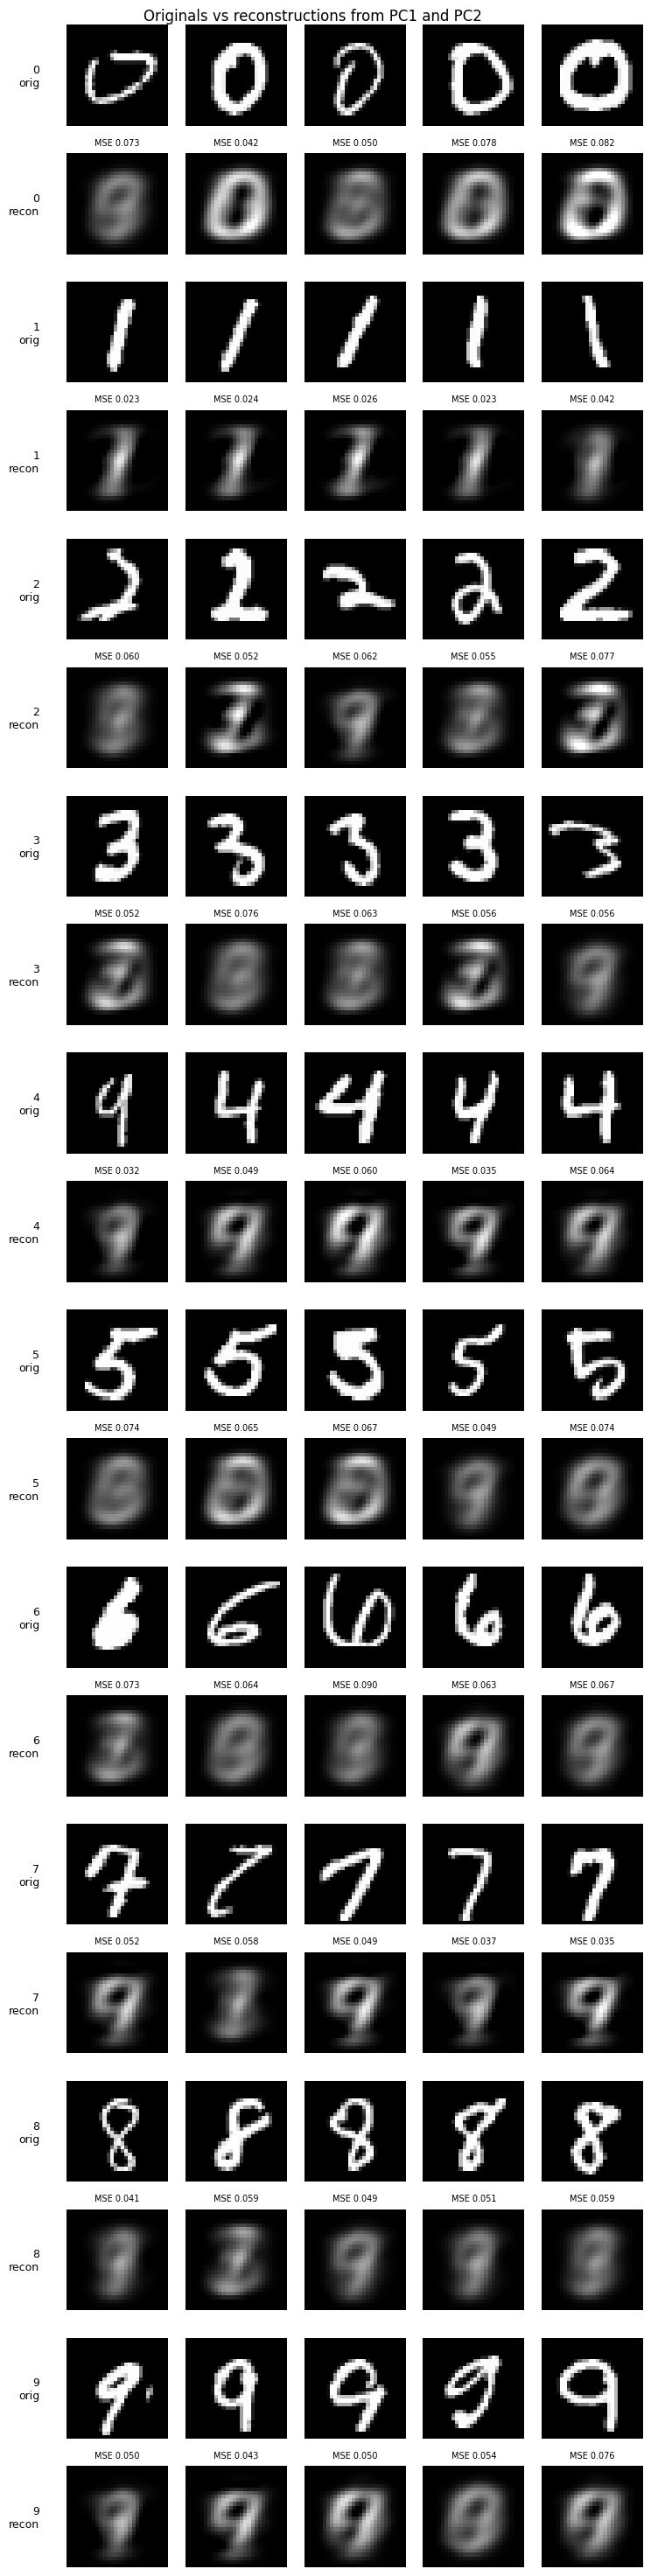

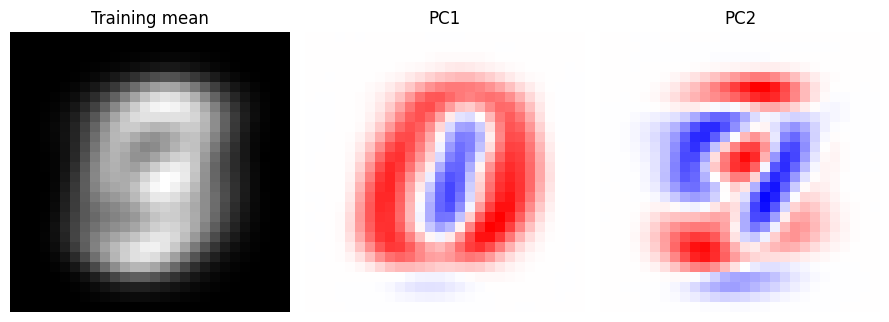

In [1]:
# Question 2 b
import glob
import os
import struct
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

DATA_DIR = kagglehub.dataset_download("hojjatk/mnist-dataset")
print("Path to dataset files:", DATA_DIR)
OUT_DIR = "./2B_outputs"
N_PER_CLASS = 5
SEED = 0
os.makedirs(OUT_DIR,exist_ok=True)

# code for loading the data
def find_file(prefix, kind):
    pattern = os.path.join(DATA_DIR,"**",f"{prefix}*{kind}*ubyte")
    hits = [p for p in glob.glob(pattern,recursive=True) if os.path.isfile(p)]
    if not hits:
        raise FileNotFoundError(f"No file matching {prefix}*{kind}*ubyte under {DATA_DIR}")
    return hits[0]

def load_idx_images(path):
    with open(path,"rb") as f:
        _,n,rows,cols = struct.unpack(">IIII", f.read(16))
        data = np.frombuffer(f.read(),dtype=np.uint8)
    return data.reshape(n,rows*cols)

def load_idx_labels(path):
    with open(path, "rb") as f:
        _, n = struct.unpack(">II", f.read(8))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(np.int64)


X_train = load_idx_images(find_file("train-images", "idx3"))
y_train = load_idx_labels(find_file("train-labels", "idx1"))
X_test = load_idx_images(find_file("t10k-images", "idx3"))
y_test = load_idx_labels(find_file("t10k-labels", "idx1"))
# normalize pixel values
X_train = X_train.astype(np.float64)/255.0
X_test = X_test.astype(np.float64)/255.0

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
assert X_train.shape == (60000, 784) and X_test.shape == (10000, 784)


# fittign PCA on training set only
pca = PCA(n_components=2,svd_solver="full")
pca.fit(X_train)

# (i) explaining variance
evr = pca.explained_variance_ratio_
total_var = X_train.var(axis=0,ddof=1).sum()
print("\n(i) Variance explained")
print(f"Total variance (trace of covariance): {total_var:.4f}")
print(f"PC1: eigenvalue = {pca.explained_variance_[0]:.4f}, ratio = {evr[0]*100:.2f}%")
print(f"PC2: eigenvalue = {pca.explained_variance_[1]:.4f}, ratio = {evr[1]*100:.2f}%")
print(f"Cumulative (PC1 + PC2): {evr.sum()*100:.2f}%")

# (ii) project test images and plot PC1 vs PC2
Z_test = pca.transform(X_test)
colors = plt.cm.tab10(np.arange(10))
markers = ["o","s","^","v","D","P","X","*","<",">"]
fig, ax = plt.subplots(figsize=(10,8))
for d in range(10):
    m = (y_test == d)
    ax.scatter(Z_test[m,0],Z_test[m,1],s=8,alpha=0.5,color=colors[d],marker=markers[d],label=str(d))
ax.set_xlabel(f"PC1 ({evr[0]*100:.2f}% variance)")
ax.set_ylabel(f"PC2 ({evr[1]*100:.2f}% variance)")
ax.set_title("MNIST test set projected onto 1st 2 principal components")
ax.legend(title="Digit",markerscale=2,loc="best")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR,"b_ii_test_scatter.png"),dpi=150)
plt.show()

# (iii) few samples per class in 2D space
rng = np.random.default_rng(SEED)
sel_idx = np.concatenate([rng.choice(np.where(y_test == d)[0],N_PER_CLASS,replace=False) for d in range(10)])
X_sel,y_sel,Z_sel = X_test[sel_idx],y_test[sel_idx], Z_test[sel_idx]
fig, ax = plt.subplots(figsize=(10,8))
ax.scatter(Z_test[:,0],Z_test[:,1],s=3,color="lightgray",alpha=0.4,label="All test images")
for d in range(10):
    m = (y_sel == d)
    ax.scatter(Z_sel[m,0],Z_sel[m,1],s=90,color=colors[d],marker=markers[d],edgecolors="black",linewidths=0.6,label=str(d))
    for z in Z_sel[m]:
        ax.annotate(str(d),z,xytext=(4,4),textcoords="offset points",fontsize=9,fontweight="bold")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"{N_PER_CLASS} selected test samples per digit in 2D PCA space")
ax.legend(title="Digit",loc="best",fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR,"b_iii_selected_samples.png"),dpi=150)
plt.show()

print("\n(iii) Per-class statistics on full test set (PC space)")
print(f"{'digit':>5} {'mean PC1':>9} {'mean PC2':>9} {'std PC1':>8} {'std PC2':>8}")
for d in range(10):
    Zd = Z_test[y_test == d]
    print(f"{d:>5} {Zd[:,0].mean():>9.3f} {Zd[:,1].mean():>9.3f} {Zd[:,0].std():>8.3f} {Zd[:,1].std():>8.3f}")

# (iv) reconbstruction from 2 principal components
X_rec = pca.inverse_transform(Z_sel)
mse = np.mean((X_sel-X_rec)**2,axis=1)
print("\n(iv) Reconstruction error with 2 PCs (selected images)")
print(f"Mean per-pixel MSE: {mse.mean():.4f}")
for d in range(10):
    print(f"Digit {d}: mean MSE = {mse[y_sel == d].mean():.4f}")

fig,axes = plt.subplots(20,N_PER_CLASS,figsize=(1.6*N_PER_CLASS,30))
for d in range(10):
    idx = np.where(y_sel == d)[0]
    for j,k in enumerate(idx):
        a_o,a_r = axes[2*d,j], axes[2*d+1,j]
        a_o.imshow(X_sel[k].reshape(28,28),cmap="gray",vmin=0,vmax=1)
        a_r.imshow(X_rec[k].reshape(28,28),cmap="gray",vmin=0,vmax=1)
        a_r.set_title(f"MSE {mse[k]:.3f}",fontsize=7)
        a_o.axis("off")
        a_r.axis("off")
    axes[2*d,0].text(-8,14,f"{d}\norig",fontsize=9,ha="right",va="center")
    axes[2*d+1,0].text(-8,14,f"{d}\nrecon",fontsize=9,ha="right",va="center")
fig.suptitle("Originals vs reconstructions from PC1 and PC2",fontsize=12)
fig.tight_layout(rect=[0.05, 0, 1, 0.99])
fig.savefig(os.path.join(OUT_DIR,"b_iv_reconstructions.png"),dpi=150)
plt.show()
fig,axes = plt.subplots(1,3,figsize=(9,3.2))
axes[0].imshow(pca.mean_.reshape(28, 28),cmap="gray")
axes[0].set_title("Training mean")
for i in range(2):
    v = np.abs(pca.components_[i]).max()
    axes[i+1].imshow(pca.components_[i].reshape(28,28),cmap="bwr",vmin=-v,vmax=v)
    axes[i+1].set_title(f"PC{i+1}")
for a in axes:
    a.axis("off")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR,"b_iv_mean_and_components.png"),dpi=150)
plt.show()

## (b) 2D Representation of MNIST

### (i) Variance explained
PCA was fit on 60,000 normalized training images (total variance = 52.73).

| Component | Eigenvalue | Variance explained |
|---|---|---|
| PC1 | 5.117 | 9.70% |
| PC2 | 3.741 | 7.10% |
| **Cumulative** | 8.858 | **16.80%** |

Only 16.8% of total variance is retained in 2D.

### (ii) Projection of test images
Test images were centered with training mean and projected as $z = U_2^T(x - \mu)$, where $U_2 = [u_1, u_2]$. The scatter plot shows PC1 vs PC2 for all 10,000 test images colored by digit.

### (iii) Observations
- Digit 1 forms a tight, well-separated cluster at negative PC1 (mean −3.33, std 0.56).
- Digit 0 lies at the opposite end, at large positive PC1 (mean 4.02). PC1 therefore mainly separates round, wide digits from thin, vertical strokes.
- PC2 separates {4, 7, 9} (mean PC2 ≈ −2.3) from {2, 3} (mean PC2 ≈ 1.4 to 1.9). Digits 4, 7 and 9 overlap almost completely because their shapes are similar.
- Digits 2, 3, 5, 6 and 8 overlap heavily near the center. Their class means are closer together than their spreads.
- Within-class spread is large. The selected samples of the same digit can lie far apart; for example, the selected 0s range from PC1 ≈ 0.3 to 6.8.
- **Conclusion:** PCA maximizes variance, not class separation. With only 16.8% of the variance kept, most classes are not separable in 2D.

### (iv) Reconstruction using 2 PCs
Reconstruction: $\hat{x} = \mu + z_1 u_1 + z_2 u_2$.

- **Retained:** coarse global structure like overall ink mass, round vs. stroke-like shape and top/bottom ink distribution. Digits 1 and wide 0s remain recognizable.
- **Lost:** fine stroke detail and for most digits, their identity. Digits 2, 3, 5, 6 and 8 reconstruct as similar blurry blobs, and 4 and 7 look like 9.
- **Error:** mean per-pixel MSE = 0.0552. This matches the discarded variance per pixel, $(52.73 - 8.86)/784 \approx 0.056$. The error is lowest for 1 (0.028) and highest for 6 (0.071).

## (c) Analysis and Interpretation

### (i) Class separation and overlap
**Well separated**
- **1:** forms a tight isolated cluster at negative PC1 (mean −3.33, std 0.56).
- **0:** sits at large positive PC1 (mean 4.02), although some thin 0s fall toward the center.

**Partially separated**
- **{4, 7, 9} vs. {2, 3}:** PC2 separates the two groups.

**Significant overlap**
- **4, 7 and 9** overlap almost completely with each other.
- **2, 3, 5, 6 and 8** overlap heavily near the center; their class means are closer together than their spreads.

**Reasons for overlap**
- **Shared strokes:** 4, 7, and 9 share an upper part with a right-side vertical stroke, and 3, 5, and 8 share curved strokes in the same pixel regions.
- **Large within-class variation:** differences in slant, thickness, and size are comparable to the differences between classes.
- **PCA is unsupervised and linear:** it maximizes variance, not class separability.
- **Little variance retained:** only 16.8% of the variance is kept, so most of the distinguishing information is discarded.

### (ii) Why 2 PCs are still useful for visualization
- PC1 and PC2 are the two directions of maximum variance. No other 2D linear projection preserves more of the data's spread.
- The average variance per pixel is $52.73/784 \approx 0.067$. PC1 (5.12) and PC2 (3.74) carry about 76× and 56× that amount, so they capture the dominant structure: ink distribution and round vs. stroke-like shape.
- This is enough to reveal the global structure of the data: distinct classes (0, 1), groups of similar digits ({4, 7, 9}), outliers, and within-class spread.
- Humans can only view 2 to 3 dimensions, so the top PCs give the most informative linear view for exploratory analysis, even if they are not sufficient for classification.

### (iii) Information lost in reducing 784 → 2 dimensions
- **Variance:** 83.2% of the total variance (43.87 of 52.73) is discarded.
- **Reconstruction error:** the mean per-pixel MSE is 0.0552, consistent with the discarded variance per pixel, $43.87/784 \approx 0.056$.
- **Lost:** fine, local features such as stroke shape, slant, thickness, open vs. closed loops, and the exact position of strokes. These are the features that distinguish similar digits (3/5/8, 4/7/9).
- **Evidence:** reconstructions of 2, 3, 5, 6, and 8 become similar blurry blobs, and 4 and 7 become 9-like. Only 1 (lowest MSE, 0.028) and wide 0s remain recognizable.
- **Retained:** coarse global information only, such as the total ink, overall shape type, and top/bottom ink distribution.

**3. Regression Models for Ordinal Data**  
**Part (c): Ordinal Regression vs Linear Regression on UCI Wine Quality**

In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score,cohen_kappa_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.miscmodels.ordinal_model import OrderedModel

# data reading
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"
red = pd.read_csv(URL + "winequality-red.csv", sep=";")
white = pd.read_csv(URL + "winequality-white.csv", sep=";")
red["is_red"], white["is_red"] = 1,0
df = pd.concat([red,white],ignore_index=True)
X = df.drop(columns="quality")
y = df["quality"]

# 80-20 split, features standardized using training set only
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler().fit(X_train)
X_train = pd.DataFrame(scaler.transform(X_train),columns=X.columns)
X_test = pd.DataFrame(scaler.transform(X_test),columns=X.columns)
y_train = y_train.reset_index(drop=True)
classes = np.sort(y_train.unique())

# ordinal regression - proportional odds model (logit link)
ordinal = OrderedModel(y_train,X_train, distr="logit").fit(method="bfgs",disp=False)
probs = np.asarray(ordinal.predict(X_test)) # P(Y = j|x) for each rating
pred_ord = classes[probs.argmax(axis=1)]

# linear regression rounded to nearest valid rating
linear = LinearRegression().fit(X_train, y_train)
pred_lin = np.clip(np.rint(linear.predict(X_test)),classes[0],classes[-1]).astype(int)

# Evaluation metrics
# MAE: average distance between predicted and true rating
# QWK: quadratic weighted kappa, agreement that penalizes far-off errors more
def evaluate(pred):
    return {"Accuracy": accuracy_score(y_test,pred),
            "MAE": mean_absolute_error(y_test,pred),
            "QWK": cohen_kappa_score(y_test,pred,weights="quadratic")}

results = pd.DataFrame({"Ordinal regression": evaluate(pred_ord),
                        "Linear regression": evaluate(pred_lin)}).T
print(results.round(4))
# fitted ordinal model - coefficients and cut points
print(ordinal.summary())

                    Accuracy     MAE     QWK
Ordinal regression    0.5346  0.5154  0.4310
Linear regression     0.5338  0.5115  0.4383
                             OrderedModel Results                             
Dep. Variable:                quality   Log-Likelihood:                -5660.2
Model:                   OrderedModel   AIC:                         1.136e+04
Method:            Maximum Likelihood   BIC:                         1.147e+04
Date:                Thu, 08 Oct 2026                                         
Time:                        16:35:08                                         
No. Observations:                5197                                         
Df Residuals:                    5179                                         
Df Model:                          12                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------

**Evaluation metric.** Accuracy treats all errors alike, but for an ordinal rating the size of the error matters. So, I am using **mean absolute error (MAE)**, the average number of rating levels a prediction is off by and **quadratic weighted kappa (QWK)**, a chance-corrected agreement that penalizes larger errors more.

**Results (20% test set)**

| Model | Accuracy | MAE | QWK |
|---|---|---|---|
| Ordinal regression | 0.5346 | 0.5154 | 0.4310 |
| Linear regression | 0.5338 | 0.5115 | 0.4383 |

**Comparison.** 2 models perform the same; the differences are within sampling noise. Ratings are concentrated at 5 and 6 and roughly evenly spaced, so treating them as numbers costs linear regression little here. Ordinal regression is still the more appropriate model: it does not assume equal spacing between ratings (the estimated cut points have unequal gaps of 2.2, 3.2, 2.6, 2.3, 3.8) and it gives a probability for each rating instead of a number that must be rounded.